<div class="alert alert-info">

➡️ Before you start, make sure that you are familiar with the **[study guide](https://liu-nlp.ai/text-mining/logistics/)**, in particular the rules around **cheating and plagiarism**.

➡️ Make sure you fill in **all** cells that say **`YOUR CODE HERE`** or **YOUR ANSWER HERE**.  You normally shouldn't need to modify any of the other cells.

➡️ Make sure that you save the notebook **with the outputs from all cells visible,** as if you had run the notebook from top to bottom.

</div>

# L2: Text Classification

<div class="alert alert-warning">

⚠️ The last problem in this lab **requires a GPU with 8GB+ VRAM.**  Unless you have such a GPU, you will likely not be able to run this part of the lab.  Remember that you can access the GPU-equipped lab rooms in B-huset – Åsgard, Egypten, Olympen – to work on this lab, preferably during the times we have booked one or more of these rooms for the course.

</div>

Text classification is the task of sorting text documents into predefined classes. The concrete problem you will be working on in this lab is the classification of speeches with respect to their political affiliation. The specific texts you are going to classify are speeches held in the [Riksdag](https://www.riksdagen.se/en/), the Swedish national legislature.  Don’t worry if you don’t understand Swedish – that’s not required to follow this lab!

## Dataset

The raw data for this lab comes from [The Riksdag’s Open Data](https://data.riksdagen.se/in-english/). We have prepared them as two compressed [JSON](https://en.wikipedia.org/wiki/JSON) files:

* `anforande-202324.json.bz2` (speeches from the 2023/2024 parliamentary session)
* `anforande-202425.json.bz2` (ditto, from the 2024/2025 session)

We start by loading these files into two separate data frames.

In [1]:
import pandas as pd
import bz2

with bz2.open("anforande-202324.json.bz2", mode="rt", encoding="utf-8") as source:
    speeches_202324 = pd.read_json(source, encoding="utf-8")

with bz2.open("anforande-202425.json.bz2", mode="rt", encoding="utf-8") as source:
    speeches_202425 = pd.read_json(source, encoding="utf-8")

When you inspect the two data frames, you can see that there are three labelled columns: `id` (the official speech ID), `text` (the entire speech), and `party` (the party of the speaker, represented by its customary abbreviation). _(There is also `wing`, roughly mapping the parties to left and right wing, but we’re not using this column in this lab.)_

In [2]:
speeches_202324.head()

,id,text,party,wing
0,HB-002-004,Eders Majestäter! Eders Kungliga Högheter! Her...,M,R
1,HB-003-001,Fru talman! Gårdagen var en firandets dag i ri...,S,L
2,HB-003-002,Fru talman! Jag yrkar bifall till Vänsterparti...,V,L
3,HB-003-003,Fru talman! Vi debatterar regeringens proposit...,SD,R
4,HB-003-004,Fru talman! Sverige är i ett nytt läge. Det är...,C,R


Throughout the lab, we will be using the speeches from **2023/2024** as our **training data**, and the speeches from **2024/2025** as our **test data**.

In [3]:
training_data, test_data = speeches_202324, speeches_202425

For later reference, we store the sorted list of party abbreviations.

In [4]:
parties = sorted(training_data["party"].unique())
print(parties)

['C', 'KD', 'L', 'M', 'MP', 'S', 'SD', 'V']


## Problem 1: Explore the dataset

Let’s start by getting to know the data better by producing a simple visualization.  More specifically, we ask you to compare the two data frames with respect to the distribution of the speeches over the different parties.

_(If you are not familiar with the Swedish political system and the parties represented in the Riksdag in particular, then we suggest that you have a look at the Wikipedia article about the [2022 Swedish general election](https://en.wikipedia.org/wiki/2022_Swedish_general_election), but it’s not required for solving this lab.  Neither is knowing Swedish!)_

<div class="alert alert-info">

Your task is to **write code to generate two bar plots** that visualize the party distribution, one for the 2023/2024 speeches and one for the 2024/2025 speeches. Inspect the two plots, and compare them

* to each other; and
* to the results of the 2022 general elections.

To facilitate the comparison, you should plot the parties in descending order of their total number of speeches.

</div>

**_Note:_** You can produce the bar plots in any way you like (e.g. with Matplotlib, Seaborn, or directly with Pandas); if you don’t know where to start, one suggestion is to look at [seaborn’s tutorial for “visualizing categorical data”](https://seaborn.pydata.org/tutorial/categorical.html), specifically the parts about making _count_ plots.

In [5]:
# Importing seaborn style — usually a good choice by default
import seaborn as sns
# sns.set()
sns.set_theme()

<Axes: xlabel='count', ylabel='party'>

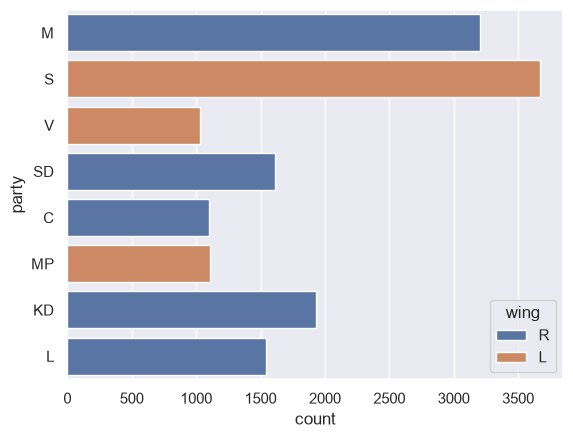

In [6]:
"""Produce a plot for the 2023/2024 speeches."""
sns.countplot(data=speeches_202324, y="party", hue="wing", legend=True)

<Axes: xlabel='count', ylabel='party'>

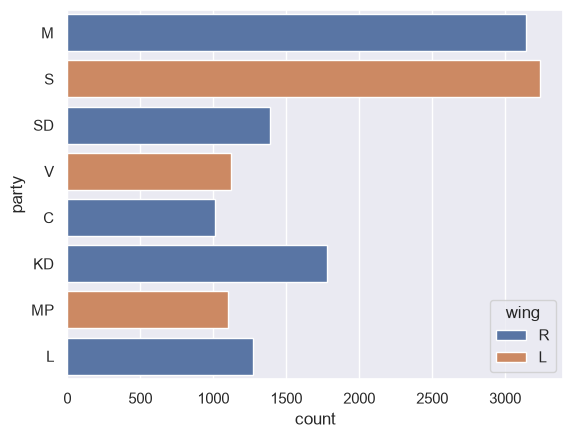

In [7]:
"""Produce a plot for the 2024/2025 speeches."""
sns.countplot(data=speeches_202425, y="party", hue="wing", legend=True)

## Problem 2: Naive Bayes classifier

You are now ready to train and evaluate a classifier. More specifically, we ask you to train a [Multinomial Naive Bayes](https://scikit-learn.org/stable/modules/naive_bayes.html#multinomial-naive-bayes) classifier. You will have to

1. vectorize the speeches in the training data _(with simple token counts)_
2. instantiate and fit the Naive Bayes model on the training data
3. evaluate the model on the test data

You can use any approach you like, but a suggestion is to use scikit-learn’s convenience [Pipeline class](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html) that allows you to solve the first two tasks with very compact code. For the evaluation you can use the function [classification_report()](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html), which will report per-class precision, recall and F1, as well as overall accuracy.

<div class="alert alert-info">

Write code to **train a Multinomial Naive Bayes classifier** as described above **and report its performance** on the test data!

</div>

In [8]:
# YOUR CODE HERE
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report

X_train, X_test = training_data['text'], test_data['text']
y_train, y_test = training_data['party'], test_data['party']

mnb = Pipeline([("vectorizer", CountVectorizer()),("classifier", MultinomialNB(alpha=0.005))])

mnb.fit(training_data["text"], training_data["party"])
predictions = mnb.predict(test_data["text"])

print(classification_report(test_data["party"], predictions))

              precision    recall  f1-score   support

           C       0.45      0.41      0.43      1012
          KD       0.61      0.51      0.56      1778
           L       0.58      0.49      0.53      1275
           M       0.61      0.65      0.63      3140
          MP       0.47      0.30      0.37      1099
           S       0.54      0.74      0.63      3237
          SD       0.48      0.42      0.45      1389
           V       0.51      0.38      0.44      1119

    accuracy                           0.55     14049
   macro avg       0.53      0.49      0.50     14049
weighted avg       0.55      0.55      0.54     14049



Would you have expected the results that you got? (No need to write anything about this just yet, but make sure you understand what the values in the report mean.)

## Problem 3: Baselines

Evaluation metrics such as accuracy or F1-score should not be understood as _absolute_ measures of performance, but should be used only to _compare_ different classifiers. When other classifiers are not available, there are some simple baselines we can use that are implemented by scikit-learn’s [DummyClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html).

One of the simplest baselines is to predict, for every document, that class which appears most often in the training data. This baseline is also called the _most frequent class_ baseline.

<div class="alert alert-info">

Write code to **fit the most-frequent-class baseline** on the training data **and report its performance** on the test data!

</div>

In [9]:
# YOUR CODE HERE
from sklearn.dummy import DummyClassifier

clf = DummyClassifier(strategy="most_frequent")
clf.fit(X_train, y_train)
predictions = clf.predict(X_test)

print(classification_report(y_test, predictions, zero_division=0))

              precision    recall  f1-score   support

           C       0.00      0.00      0.00      1012
          KD       0.00      0.00      0.00      1778
           L       0.00      0.00      0.00      1275
           M       0.00      0.00      0.00      3140
          MP       0.00      0.00      0.00      1099
           S       0.23      1.00      0.37      3237
          SD       0.00      0.00      0.00      1389
           V       0.00      0.00      0.00      1119

    accuracy                           0.23     14049
   macro avg       0.03      0.12      0.05     14049
weighted avg       0.05      0.23      0.09     14049



In [10]:
# YOUR CODE HERE
clf = DummyClassifier(strategy="stratified", random_state=42)
clf.fit(X_train, y_train)
predictions = clf.predict(X_test)

print(classification_report(y_test, predictions, zero_division=0))

              precision    recall  f1-score   support

           C       0.07      0.07      0.07      1012
          KD       0.13      0.13      0.13      1778
           L       0.10      0.11      0.10      1275
           M       0.22      0.21      0.21      3140
          MP       0.07      0.07      0.07      1099
           S       0.23      0.24      0.24      3237
          SD       0.10      0.11      0.10      1389
           V       0.08      0.07      0.08      1119

    accuracy                           0.16     14049
   macro avg       0.13      0.13      0.13     14049
weighted avg       0.16      0.16      0.15     14049



As you saw in Problem&nbsp;1, the distribution of the speeches over the eight different parties (classes) is imbalanced. One technique used to alleviate this is **undersampling**, in which one randomly removes samples from over-represented classes until all classes are represented with the same number of samples.

<div class="alert alert-info">

Your task here is to **implement undersampling to create a balanced subset of the training data**. Afterwards, **rerun the evaluation** from Problem&nbsp;2 on the balanced data and compare the results.

</div>

_Hint:_ Your balanced subset should consist of 8,264 speeches.

In [11]:
"""Implement undersampling with the classifier from Problem 2 and report its performance on the test data."""

# YOUR CODE HERE
min_counts = training_data["party"].value_counts().min()
balanced_data = training_data.groupby("party", group_keys=False).sample(
    n=min_counts, random_state=42
)

print(len(balanced_data))

vectorizer = CountVectorizer()
X_train_balanced = vectorizer.fit_transform(balanced_data["text"])
X_test_balanced = vectorizer.transform(test_data["text"])

clf_balanced = MultinomialNB(alpha=0.005)
clf_balanced.fit(X_train_balanced, balanced_data["party"])
predictions_balanced = clf_balanced.predict(X_test_balanced)

print(classification_report(test_data["party"], predictions_balanced, zero_division=0))

8264
              precision    recall  f1-score   support

           C       0.32      0.58      0.41      1012
          KD       0.56      0.50      0.53      1778
           L       0.51      0.50      0.50      1275
           M       0.66      0.50      0.57      3140
          MP       0.37      0.39      0.38      1099
           S       0.64      0.50      0.56      3237
          SD       0.40      0.47      0.43      1389
           V       0.38      0.56      0.45      1119

    accuracy                           0.50     14049
   macro avg       0.48      0.50      0.48     14049
weighted avg       0.53      0.50      0.51     14049



## Problem 5: Confusion matrix

A _confusion matrix_ is a type of table that is useful when analysing the performance of a classifier. In this table, both the rows and the columns correspond to classes, and each cell $(i, j)$ states how many times a sample with _gold-standard_ class $i$ was _predicted_ as belonging to class $j$.

In scikit-learn, a simple way to visualize the confusion matrix as a _heatmap_ is to use [ConfusionMatrixDisplay](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ConfusionMatrixDisplay.html).  The following cell demonstrates how to compute and display a confusion matrix for the classifier in the `model` variable — you may have to adjust this based on the code you have written for your previous solutions:

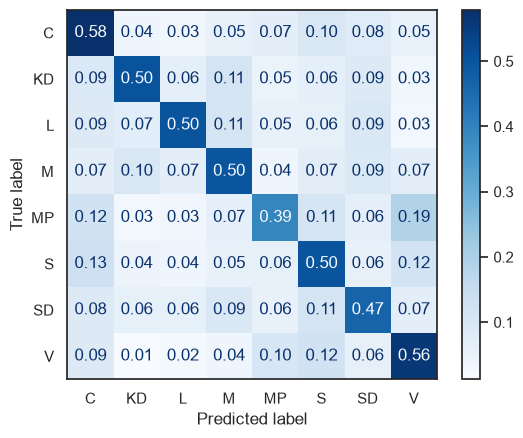

In [12]:
from sklearn.metrics import ConfusionMatrixDisplay

with sns.axes_style("white"):  # Seaborn’s default style doesn’t play well with ConfusionMatrixDisplay, so we change it temporarily
    ConfusionMatrixDisplay.from_predictions(
        test_data["party"],                 # The correct (gold-standard) labels
        predictions_balanced,
        normalize="true",
        values_format=".2f",
        cmap=sns.color_palette("Blues", as_cmap=True),
    )

<div class="alert alert-info">

Your task is to use the confusion matrix in order to find, for each given party $p$ in the Riksdag, that other party $p'$ which the classifier that you trained in Problem&nbsp;4 most often confuses with $p$ when it predicts the party of a speaker.

You can read this off of the visualization above, but for the purposes of this exercise, we want to do this programmatically (i.e. with code).  For this, you most likely want to use the scikit-learn function [confusion_matrix()](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html), which gives you the confusion matrix of a classifier.

**Write code that, for each party $p$, prints the party most often confused with $p$ by the classifier from Problem 4!**

</div>

In [13]:
from sklearn.metrics import confusion_matrix
import numpy as np

matrix = confusion_matrix(test_data["party"], predictions_balanced, labels=parties)
np.fill_diagonal(matrix, 0)

for i, party in enumerate(parties):
    if matrix[i].max() == 0:
        print(f"{party}: no incorrect predictions")
    else:
        confused_party = parties[matrix[i].argmax()]
        print(f"{party} most often confused with: {confused_party} ({matrix[i].max()} speeches)")


C most often confused with: S (100 speeches)
KD most often confused with: M (201 speeches)
L most often confused with: M (136 speeches)
M most often confused with: KD (308 speeches)
MP most often confused with: V (209 speeches)
S most often confused with: C (423 speeches)
SD most often confused with: S (154 speeches)
V most often confused with: S (133 speeches)


Before you move on, take a minute to reflect on whether your results make sense.

## Problem 6: Fine-tuning a BERT model

Until now, we have only used “classical” statistical methods for training text classifiers.  In this last part of the lab, we will see how we can fine-tune a modern, pre-trained language model based on the BERT architecture.

We will be using the popular [Huggingface ecosystem](https://huggingface.co/docs) of models and Python libraries.  The code we’re giving you below is largely based on Huggingface’s [text classification guide](https://huggingface.co/docs/transformers/v5.20.1/en/tasks/sequence_classification).  Training and fine-tuning neural networks is quite an intricate process, with more code and parameters than we’ve seen for Naive Bayes above, and our focus here will not be on understanding every technical aspect of this, but on how to apply this correctly to our problem of parliamentary speech classification.

Since our data is in Swedish, we can use any pretrained BERT model that supports Swedish.  One way to find such models on Huggingface is by [filtering for the "Fill-Mask" task and "Swedish" language](https://huggingface.co/models?pipeline_tag=fill-mask&language=sv).  Here, we are going to use a Swedish BERT model trained by researchers at the National Library of Sweden, which is on Huggingface as [KBLab/bert-base-swedish-cased](https://huggingface.co/KBLab/bert-base-swedish-cased).

In [14]:
from pathlib import Path
from liu_tm.torch import check_gpu

check_gpu()
# This part checks if we’re on the lab computers, and loads the model from there
model_name = Path("/courses/TDDE16/models/KBLab/bert-base-swedish-cased")
if not model_name.exists():
    model_name = "KBLab/bert-base-swedish-cased"

### Preparing the dataset

Before we can fine-tune the model, we need to turn the dataset into a format that Huggingface can use.  One way to do this is by using the [datasets](https://huggingface.co/docs/datasets/index) library.  Here is how to load our JSON files from before using this library:

In [15]:
from datasets import load_dataset

dataset = load_dataset("json", data_files={
    "train": "anforande-202324.json.bz2",
    "test": "anforande-202425.json.bz2",
})
dataset = dataset.rename_columns({"party": "label"}).remove_columns("wing")
dataset

DatasetDict({
    train: Dataset({
        features: ['id', 'text', 'label'],
        num_rows: 15195
    })
    test: Dataset({
        features: ['id', 'text', 'label'],
        num_rows: 14049
    })
})

We currently have "train" and "test" splits. For neural network training and fine-tuning, it can be very useful to also have a "validation" split, which can be used during training e.g. to perform intermediate evaluations and decide when to stop training or which model checkpoint performed best. Ideally, just like the "test" data, this validation data should be as independent as possible from the training data.

In our dataset, the IDs for each speech follow the format `HB-<sitting>-<speech>`.  One way to split off some validation data is therefore to make sure we always use entire "sittings" for the split.

<div class="alert alert-info">

Create a validation set out of the **last ~10% of the training data**, **split by sittings** (i.e., all speeches from the same sitting should end up in the same split).

This means you’ll need to find a cutoff point (i.e. a sitting number) where approximately 90% of the speeches come before it, then use everything before the cutoff for "train", and everything after as "validation".  To be clear, make sure that you also update the "train" set to not include the "validation" data anymore!

</div>

_Hint:_ `dataset` behaves like a dictionary, and the individual entries (e.g. `dataset["train"]`) have useful utility methods that are described in the [documentation on selecting and filtering datasets](https://huggingface.co/docs/datasets/v4.8.4/process#select-and-filter).

In [16]:
from collections import Counter

train_data = dataset["train"]
sittings = [int(speech_id.split("-")[1]) for speech_id in train_data["id"]]
sitting_counts = Counter(sittings)

target = len(train_data) * 0.9
count = 0
cutoff = None
closest = float("inf")
for sitting in sorted(sitting_counts):
    if abs(count - target) < closest:
        cutoff = sitting
        closest = abs(count - target)
    count += sitting_counts[sitting]

train_indices = [i for i, sitting in enumerate(sittings) if sitting < cutoff]
validation_indices = [i for i, sitting in enumerate(sittings) if sitting >= cutoff]

dataset["train"] = train_data.select(train_indices)
dataset["validation"] = train_data.select(validation_indices)

print(f"Cutoff sitting: {cutoff}")
print(f"Train: {len(dataset['train'])}, validation: {len(dataset['validation'])}")


Cutoff sitting: 125
Train: 13639, validation: 1556


If your implementation is correct, you should end up with 13639 rows in "train", and 1556 in "validation".

In [17]:
# Show what "dataset" looks like now:
dataset

DatasetDict({
    train: Dataset({
        features: ['id', 'text', 'label'],
        num_rows: 13639
    })
    test: Dataset({
        features: ['id', 'text', 'label'],
        num_rows: 14049
    })
    validation: Dataset({
        features: ['id', 'text', 'label'],
        num_rows: 1556
    })
})

After we have produced the desired data split, we still need to run some more preprocessing.  The code below creates dictionaries mapping our labels (the party abbreviations) to numeric indices and vice versa, and loads and runs the tokenizer for our chosen model.

In [18]:
from transformers import AutoTokenizer, DataCollatorWithPadding

# Create mappings between labels and numerical IDs
parties = sorted(dataset["train"].unique("label"))
label2id = {label: i for i, label in enumerate(parties)}
id2label = {i: label for label, i in label2id.items()}
dataset = dataset.map(lambda x: {"label": label2id[x["label"]]})

# Select the tokenizer for our chosen model
tokenizer = AutoTokenizer.from_pretrained(model_name)
# Tokenize our entire dataset
tokenized = dataset.map(
    # NOTE: The Swedish BERT model has a maximum length of 512 tokens,
    # so documents longer than this will get cut off.  There are ways
    # to deal with this problem, but we do not look into them here.
    lambda b: tokenizer(b["text"], truncation=True, max_length=512),
    batched=True,
)
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

### Preparing the evaluation metrics

The following code prepares a simple function that computes evaluation metrics, this time using the Huggingface [evaluate](https://huggingface.co/docs/evaluate/index) library so that we can easily integrate them into the training process:

In [19]:
import evaluate
import numpy as np

accuracy = evaluate.load("accuracy")
f1 = evaluate.load("f1")

def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis=1)
    return {
        **accuracy.compute(predictions=predictions, references=labels),
        "f1_macro": f1.compute(predictions=predictions, references=labels, average="macro")["f1"],
    }

W1110 13:48:37.507000 96200 course-materials/.venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


### Fine-tuning the model

We are finally ready to load and fine-tune our Swedish BERT model.  The following cell instantiates the model. Note:

- If you are **not** running this on the lab computers, the first time you run this, it will **automatically download the `KBLab/bert-base-swedish-cased` model** (up to ~2.2 GB of data).
- Loading this model will **print some warnings** about unexpected and missing parameters; this is totally normal, since we are instantiating a model for a text classification task _that was not yet trained on a text classification task_.

In [20]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=len(parties),
    id2label=id2label,
    label2id=label2id,
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: KBLab/bert-base-swedish-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


The following cell actually trains (fine-tunes) the model.  **This will take a while.**

There’s quite a lot going on here – training a transformer model comes with many adjustable hyperparameters.  If you run this on the lab computers, **everything should work as is**. However, if you run into issues running this on a different computer, or if you want to adapt this code for your course project, we have left some comments explaining some commonly tweaked parameters.  You may also want to check the Huggingface documentation, e.g. the docs for [TrainingArguments](https://huggingface.co/docs/transformers/v5.20.1/en/main_classes/trainer#transformers.TrainingArguments).

In [22]:
from transformers import TrainingArguments, Trainer

training_args = TrainingArguments(
    output_dir="out",
    learning_rate=2e-5,
    # With fp16=True, we use 16-bit precision instead of 32-bit precision,
    # which may make the model slightly worse, but saves GPU memory
    fp16=True,
    # Batch size is the most important parameter to save GPU memory –
    # if you run into OOM (out-of-memory) errors, reduce this number first!
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    # Total number of training epochs (i.e., how many times do we go over
    # the entire training set?) – lower this number to reduce the total
    # training time, at the cost of potentially having a worse model
    num_train_epochs=2,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="best",
    save_only_model=True,
    save_total_limit=1,
    load_best_model_at_end=True,
    dataloader_pin_memory=False
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized["train"],
    eval_dataset=tokenized["validation"],
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

from transformers.utils.notebook import NotebookProgressCallback
from transformers.trainer_callback import ProgressCallback

# There is currently a bug with the output in Jupyter notebooks,
# so we swap out the callback that shows the training progress:
trainer.remove_callback(NotebookProgressCallback)
trainer.add_callback(ProgressCallback)

# Start the training!
trainer.train()

  0%|          | 0/854 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

{'eval_loss': '1.199', 'eval_accuracy': '0.6138', 'eval_f1_macro': '0.5755', 'eval_runtime': '19.3', 'eval_samples_per_second': '80.64', 'eval_steps_per_second': '1.296', 'epoch': '1'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '1.236', 'grad_norm': '10.15', 'learning_rate': '8.314e-06', 'epoch': '1.171'}


  0%|          | 0/25 [00:00<?, ?it/s]

{'eval_loss': '1.037', 'eval_accuracy': '0.6542', 'eval_f1_macro': '0.6244', 'eval_runtime': '19.37', 'eval_samples_per_second': '80.32', 'eval_steps_per_second': '1.29', 'epoch': '2'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'train_runtime': '1920', 'train_samples_per_second': '14.21', 'train_steps_per_second': '0.445', 'train_loss': '1.069', 'epoch': '2'}


TrainOutput(global_step=854, training_loss=1.0691158464418362, metrics={'train_runtime': 1919.7928, 'train_samples_per_second': 14.209, 'train_steps_per_second': 0.445, 'total_flos': 7176954425716224.0, 'train_loss': 1.0691158464418362, 'epoch': 2.0})

Since this took a while to run, we should save the final model so that we can re-load it later, instead of repeating the entire training process:

In [23]:
# Save the model:
trainer.save_model("out/final")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

The following cell shows how we could load the model again, and is provided just for reference – if you just trained the model, you can just skip this for now.

In [24]:
def load_final_model():
    from transformers import Trainer

    model = AutoModelForSequenceClassification.from_pretrained(
        "out/final", num_labels=len(parties), id2label=id2label, label2id=label2id,
    )
    trainer = Trainer(model=model, processing_class=tokenizer)

    from transformers.utils.notebook import NotebookProgressCallback
    from transformers.trainer_callback import ProgressCallback

    trainer.remove_callback(NotebookProgressCallback)
    trainer.add_callback(ProgressCallback)

    return model, trainer

# Uncomment the following line if you want to load your trained model:
#model, trainer = load_final_model()

### Evaluating the model on test data

Finally, let’s run the same evaluations that we did above for Naive Bayes on our newly fine-tuned BERT model. The following cell runs the model on the test set to generate predictions for every speech:

In [25]:
output = trainer.predict(tokenized["test"])

  0%|          | 0/220 [00:00<?, ?it/s]

The predictions of the model are in `output.predictions`, and contain activations for every possible output class, the highest of which should be considered the class predicted by the model.  The correct labels (according to our test data) are in `output.label_ids`. The following cell illustrates how to interpret the model output:

In [26]:
print("Predictions for the first test example:")
print(output.predictions[0])
print()

y_pred = np.argmax(output.predictions[0])
print(f"Highest value at index: {y_pred}")
print(f"Predicted class: {parties[y_pred]}")
print(f"  Correct class: {parties[output.label_ids[0]]}")

Predictions for the first test example:
[-1.9394531   0.80908203  1.2900391   4.5429688  -2.3652344  -1.0019531
 -0.17077637 -1.7109375 ]

Highest value at index: 3
Predicted class: M
  Correct class: M


<div class="alert alert-info">

Write code to **perform the same evaluations for the fine-tuned BERT model** that we did in Problems 4 and 5:

1. Print a classification report.
2. Display a confusion matrix.

Make sure that both the classification report and the confusion matrix **display the party labels**, i.e. not just the numeric indices.

</div>

You should be able to do this by copying most of the relevant code from the previous exercises; the main thing you need to do is bring the outputs into the right format.

              precision    recall  f1-score   support

           C       0.69      0.46      0.55      1012
          KD       0.71      0.61      0.66      1778
           L       0.68      0.65      0.67      1275
           M       0.68      0.78      0.72      3140
          MP       0.59      0.44      0.50      1099
           S       0.71      0.80      0.75      3237
          SD       0.53      0.54      0.54      1389
           V       0.54      0.55      0.54      1119

    accuracy                           0.66     14049
   macro avg       0.64      0.60      0.62     14049
weighted avg       0.66      0.66      0.65     14049



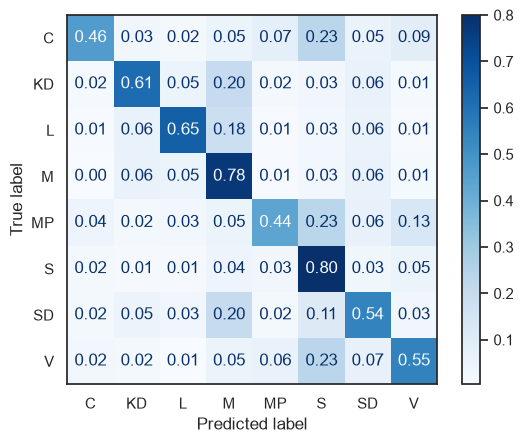

In [27]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import numpy as np

predictions = np.argmax(output.predictions, axis=1)
y_test = [id2label[label] for label in output.label_ids]
y_pred = [id2label[label] for label in predictions]

print(classification_report(y_test, y_pred, labels=parties, zero_division=0))

with sns.axes_style("white"):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=parties,
        normalize="true",
        values_format=".2f",
        cmap=sns.color_palette("Blues", as_cmap=True),
    )


## Individual reflection

<div class="alert alert-warning">

**After you have solved the lab,** save the notebook and **work on the following part individually.**

</div>

<div class="alert alert-info">

**Write a _brief_ reflection according to the instructions below.**

- You may discuss the questions with your lab partner, but remember to write them up individually.  **Do not copy** answers from your lab partner.
- You may add more cells below (even code cells!) if you wish.

</div>

In this lab, you have produced evaluation reports for a total of five classifiers:

- two baselines (most frequent class & random sampling)
- Naive Bayes with all data & with balanced data
- fine-tuned Swedish BERT classifier

Summarize the results from your evaluations, and discuss how you interpret them. What do they mean for the usefulness of each classifier? What conclusion do you draw from these results? Refer to specific evaluation scores that you find particularly relevant for your argument.

- **Always predicting the majority class**, reaches an accuracy of $23$%, because the majority class $S$ makes up $23$% of the training data. But since it never classifies any other class, accuracy is a misleading metric here.
- **Drawing a label at random** from the label distribution in the training data gives accuracy of $16$% and a $13$% macro F1. Both methods above have obvious shortcomings as they never use the actual text, but it provides lower bound for the other models to beat.
- **Using Naive Bayes**, the Accuracy goes up to $55$%, but recall for the classes varies quite substantially. S with $0.74$, whereas MP with $0.3$ is rather insufficient.
- As the dataset is unbalanced, we **undersample the majority classes** and retrain the naive bayes classifier. This helps improve recall for some parties that were less represented, like C going from $0.41$ to $0.58$. But the original majority class S falls from $0.74$ to $0.5$ and the overall accuracy and Macro F1 decrease slightly from $0.55$ -> $0.50$ and $0.5$ -> $0.48$, respectively. Balancing the classes does not seem to improve the overall strength of the Naive Bayes.
- Looking at the **confusion matrix**, interestingly the model predicts KD for $308$ M speeches, and V for $209$ MP speeches. Looking at a political compass from August $2026$ (https://www.politicalcompass.org/sweden2026) we see that the christian democrats and moderate party are quite similar as they both authoritarian, right-leaning parties, so there content likely overlaps, resulting in the model to struggle with seperating the two. Adjacently, with the left- and green-party being Libertarian left-leaning parties, a similar confusion arises. This is however just speculation, no scientific conclusion.
- **Fine-tuning the BERT model** yielded the strongest overall accuracy and Macro F1 yet, with $0.65$ and $0.5$ respectively. Scores still differ by party with recall for S being around $0.82$ yet merely $0.42$ for MP. The stronger overall score still does not mean that the model classifies equally well for overy party. Also worth considering is that training of the BERT model took **SIGNIFICANTLY** longer, than the Naiva Bayes classifier, while performing somewhat similiar. So the practical cost needs to be weighed against its only slightly higher scores.

**Congratulations on finishing this lab! 👍**

<div class="alert alert-info">

➡️ Remember that each student should submit their own version of this notebook, with their own individual answers to the reflection questions.

</div>